# Can recorded HR and activity distinguish perceived-stress categories?
## Notebook 12 · exploratory development classification

**Primary question:** does adding recorded physiology improve participant-held-out classification beyond survey category and local time?

We use the study's **three-item perceived-stress composite (3–15)**, not PSS-10 or PHQ-9.
The thresholds are exploratory, not clinical diagnoses. All 32 final-test participants remain sealed.

This presentation reads only privacy-reviewed aggregate results. Model fitting was executed separately
through the reproducible entrypoint below; rerunning these cells does not refit or touch sensor records.
No participant identifiers, actual timestamps, complete records or individual predictions are displayed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'reports').exists() else Path.cwd().parent
RESULTS = ROOT / 'reports/pss_classification/8970bf5ebcc47bfd'
pd.options.display.float_format = '{:.3f}'.format
pd.options.display.max_columns = 15

def table(name):
    return pd.DataFrame(json.loads((RESULTS / f'{name}.json').read_text()))

def figure(name):
    display(Image(filename=str(RESULTS / 'figures' / f'{name}.png')))

metrics = table('metrics')
differences = table('paired_differences')
print('Aggregate source:', RESULTS.relative_to(ROOT))
display(pd.DataFrame([json.loads((RESULTS / 'packages.json').read_text())]))

Aggregate source: reports/pss_classification/8970bf5ebcc47bfd


,lightgbm,numpy,pandas,scikit-learn,xgboost
0,4.6.0,2.2.6,2.3.3,1.9.1,3.0.5


### The target and a synthetic example
The verified stored items each use 1–5. Compute `nervous + (6 − cope) + (6 − control)` only when all three are valid.

A **synthetic** response with nervous=4, cope=2, control=3 has score 11 → high class.
A score of 4 maps to low; 5 and 9 to middle; 10 to high. No outcome is imputed.

| Task | Definition | Role |
|---|---|---|
| Three classes | low 3–4 / middle 5–9 / high 10–15 | Primary, eight lookbacks |
| Binary ≥5 | 3–4 versus 5–15 | Secondary, 60 minutes |
| Binary ≥10 | 3–9 versus 10–15 | Secondary, 60 minutes |

Macro F1 gives each class equal weight, but discretization discards differences within a class.
Classification performance cannot be compared numerically with regression MAE.

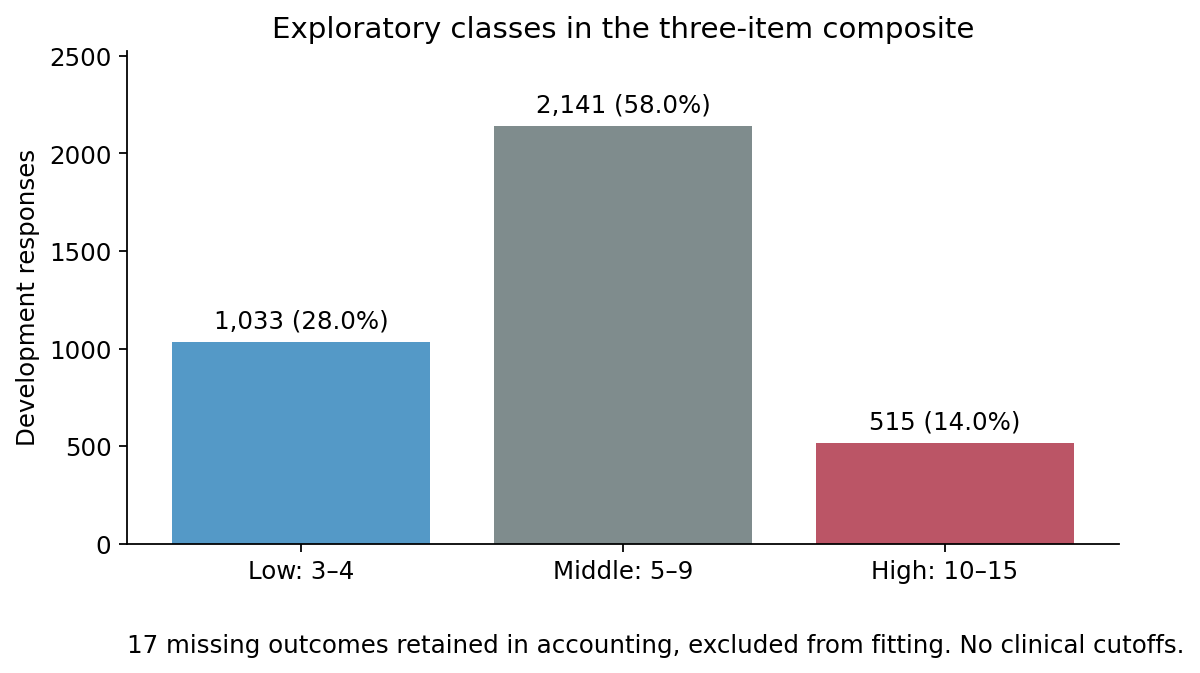

,label,participants,responses,survey_category,task
4,0,75,274,Endday,three_class
5,1,116,542,Endday,three_class
6,2,57,116,Endday,three_class
7,missing,2,2,Endday,three_class
8,0,88,532,Midday,three_class
9,1,121,1052,Midday,three_class
10,2,81,242,Midday,three_class
11,missing,11,12,Midday,three_class
12,0,68,227,Morning,three_class
13,1,118,547,Morning,three_class


In [2]:
figure('01_class_distribution')
display(table('class_distribution').query("task == 'three_class' and survey_category != 'All'"))

### What was frozen before fitting?
The primary benchmark is **60-minute joint complete cases, unweighted**. The specification was written
before classification performance. It follows earlier regression exploration and is not independent confirmation.

- Existing frozen five outer participant folds; three grouped inner folds within each outer training set.
- Majority dummy; logistic regression (four C values); XGBoost and LightGBM (12 fixed candidates each).
- Select settings by inner macro F1. No outer early stopping, threshold search or calibration.
- Context, +HR, and +HR+steps share the **same training and validation responses** in each cohort.
- All eight lookbacks, balanced training weights and feature-level imputation are specified sensitivities.
- Reference features are an additional 60-minute comparison, using only earlier unlabeled wearable data.

Class weights are recomputed from each training split. Imputation medians, scaling and category encoding
are learned inside each training split. Validation outcomes never choose settings.
See `reports/pss_classification/specification.md` and `config/pss_classification.json` for the complete search.

In [3]:
display(table('cohort_accounting').query("task == 'three_class' and cohort == 'joint' and included == True and fold == 'All' and survey_category == 'All'")[[ 'minutes','handling','responses','participants','class_0','class_1','class_2']])

,minutes,handling,responses,participants,class_0,class_1,class_2
0,5,complete,625,104,168,381,76.000
48,5,imputed,3689,125,1033,2141,515.000
91,15,complete,919,111,262,540,117.000
139,15,imputed,3689,125,1033,2141,515.000
182,30,complete,1146,113,323,677,146.000
230,30,imputed,3689,125,1033,2141,515.000
273,60,complete,1355,113,384,808,163.000
321,60,imputed,3689,125,1033,2141,515.000
364,120,complete,1585,118,445,948,192.000
412,120,imputed,3689,125,1033,2141,515.000


### Features and observation limits
HR inputs are existing mean, sample SD, latest value and slope. Steps are supported counter additions,
not assumed activity during unrecorded time. No new physiological features are calculated.

For a **synthetic** 09:22 minute-resolution start, the cutoff is 09:21. A 60-minute window is
[08:21, 09:21). A second-resolution 09:22:35 start uses [08:22:35, 09:22:35).
Missing HR summaries remain missing in complete-case analysis. In the imputed branch, only the model's
feature vector is filled using training medians, with missingness flags; no raw readings are invented.

Two readings do not establish representative coverage. Acquisition versus receipt timing, batching,
activity-counter semantics and mismatch with survey recall periods remain unresolved.

### Primary result: compare models and physiological increments separately
Every bar uses the same 1,355 responses from 113 participants. Higher macro F1 than the dummy does
not by itself show that HR helps: compare each wearable model with its matching context model.

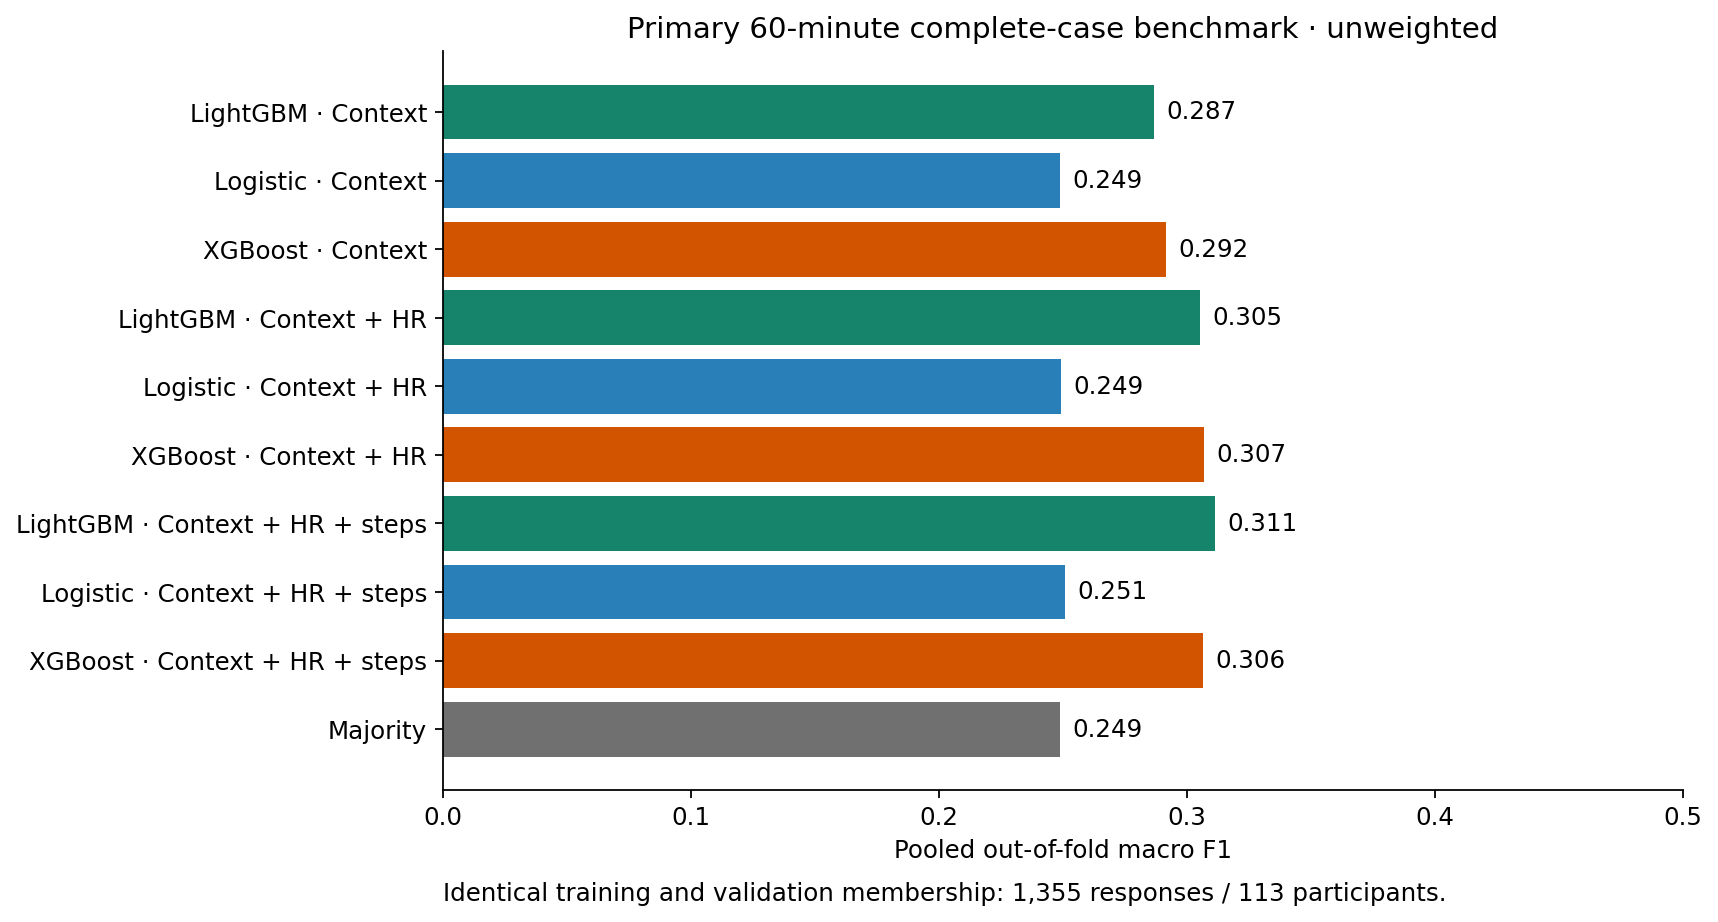

,view,model,macro_f1,balanced_accuracy,accuracy,weighted_f1,roc_auc,equal_participant_macro_f1
368,context,lightgbm,0.287,0.331,0.562,0.468,0.494,0.278
370,context,logistic,0.249,0.333,0.596,0.446,0.453,0.243
372,context,xgboost,0.292,0.332,0.558,0.469,0.484,0.286
374,context_hr,lightgbm,0.305,0.336,0.552,0.477,0.468,0.297
376,context_hr,logistic,0.249,0.333,0.596,0.446,0.461,0.243
378,context_hr,xgboost,0.307,0.335,0.545,0.476,0.468,0.296
380,context_hr_steps,lightgbm,0.311,0.338,0.548,0.480,0.469,0.308
382,context_hr_steps,logistic,0.251,0.334,0.596,0.447,0.464,0.247
384,context_hr_steps,xgboost,0.306,0.335,0.546,0.474,0.465,0.287
385,dummy,dummy,0.249,0.333,0.596,0.446,0.500,0.243


In [4]:
figure('02_primary_models')
primary = metrics.query("experiment == 'three_class__60m__joint__complete' and weighting == 'none'")
display(primary[['view','model','macro_f1','balanced_accuracy','accuracy','weighted_f1','roc_auc','equal_participant_macro_f1']])

In [5]:
display(differences.query("experiment == 'three_class__60m__joint__complete' and weighting == 'none' and view == 'context_hr_steps' and comparison in ['dummy','context','logistic','incremental_steps']")[[ 'model','comparison','macro_f1_difference','difference_low','difference_high','responses','participants']])

,model,comparison,macro_f1_difference,difference_low,difference_high,responses,participants
1313,lightgbm,context,0.025,-0.003,0.051,1355,113
1314,lightgbm,incremental_steps,0.006,-0.014,0.026,1355,113
1315,lightgbm,logistic,0.061,0.038,0.084,1355,113
1316,lightgbm,dummy,0.062,0.040,0.086,1355,113
1321,logistic,context,0.002,-0.000,0.006,1355,113
1322,logistic,incremental_steps,0.002,-0.001,0.006,1355,113
1323,logistic,dummy,0.002,-0.000,0.006,1355,113
1329,xgboost,context,0.015,-0.010,0.037,1355,113
1330,xgboost,incremental_steps,-0.001,-0.022,0.020,1355,113
1331,xgboost,logistic,0.056,0.034,0.076,1355,113


The intervals resample participants, keeping their responses together. They describe uncertainty
conditional on the saved predictions and this exploratory workflow. They do not repeat tuning or correct
for the many comparisons. A point improvement or an isolated interval is not independent validation.

### Can the high class be detected?
Confusion-matrix rows are observed classes; columns are predictions. A model can improve macro F1
mainly by separating low from middle while still missing nearly every high response.
Balanced fitting changes errors and probabilities; it does not create new evidence or guarantee calibration.

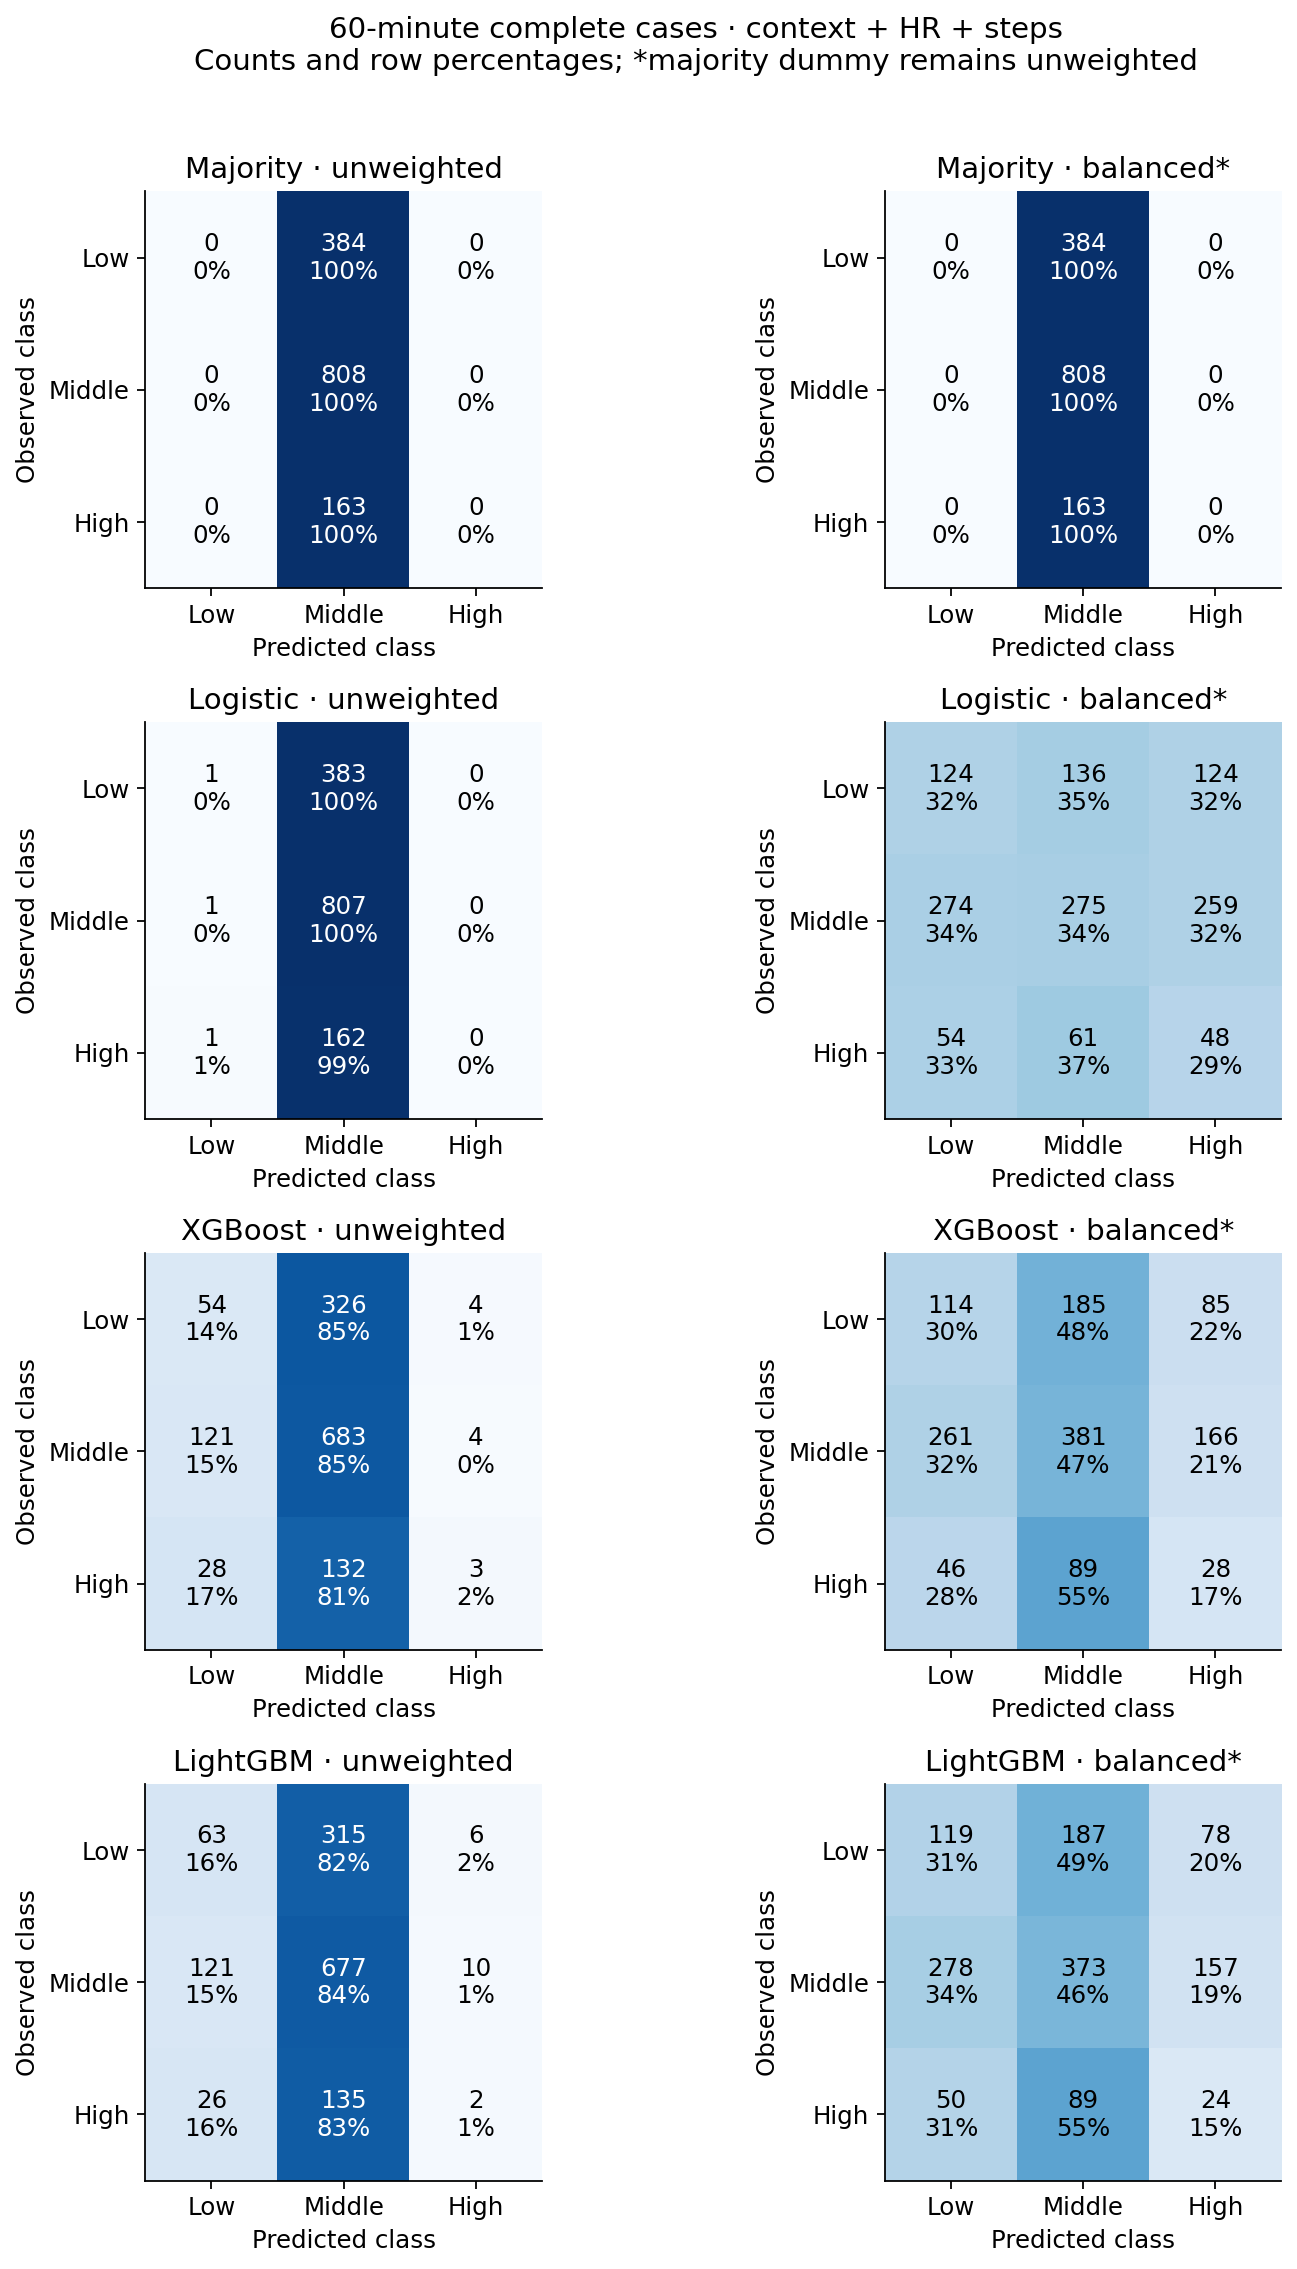

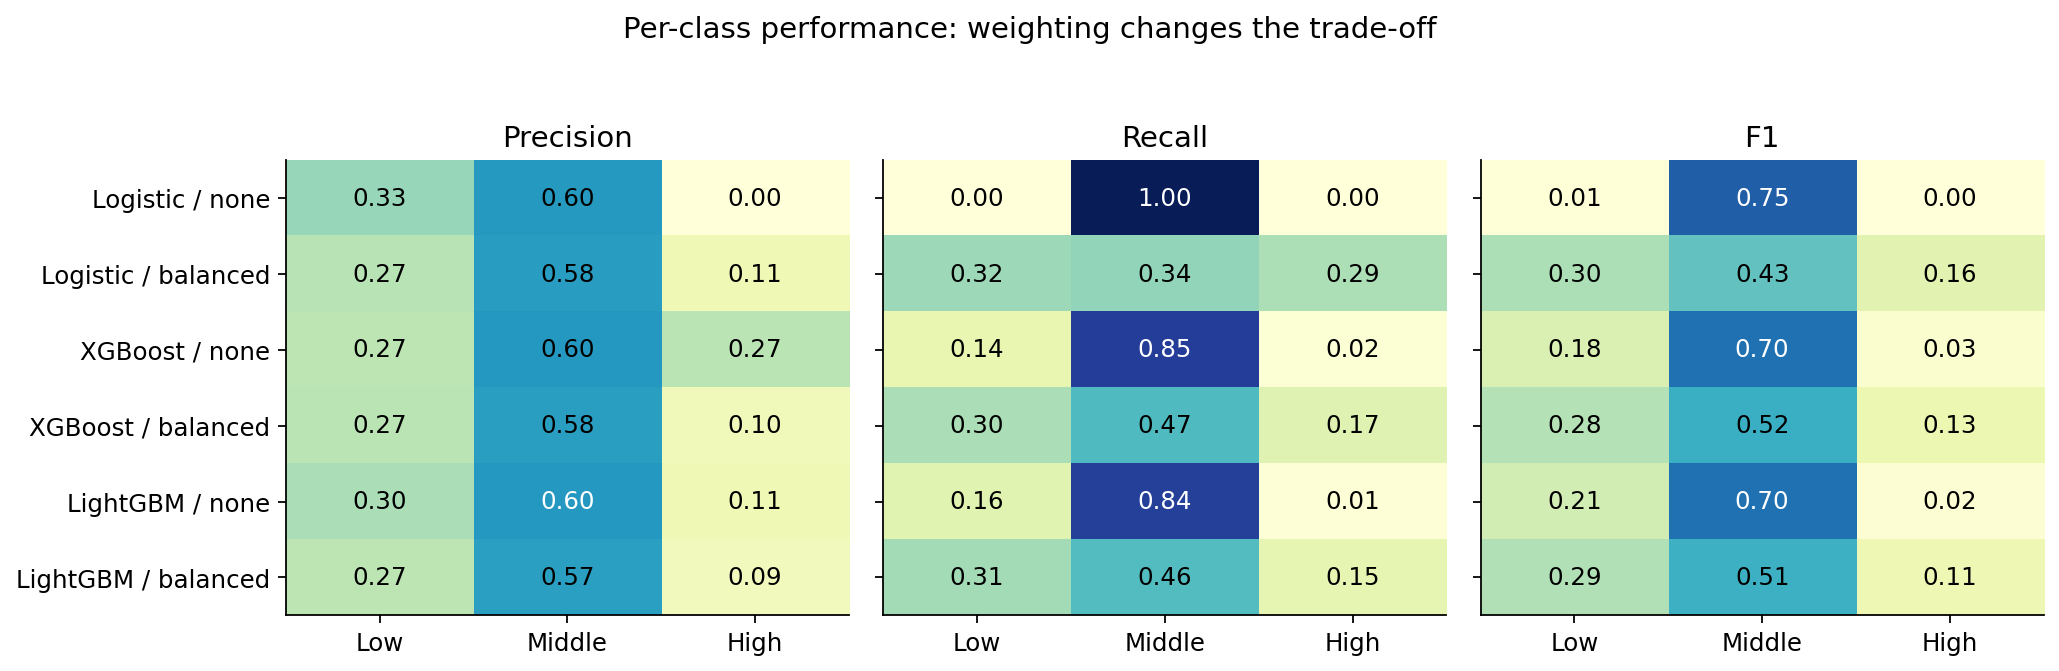

In [6]:
figure('03_confusion_matrices')
figure('04_per_class')

In [7]:
display(metrics.query("experiment == 'three_class__60m__joint__complete' and view == 'context_hr_steps'")[[ 'model','weighting','elevated_precision','elevated_recall','elevated_f1','elevated_pr_auc','predicted_elevated_fraction']])

,model,weighting,elevated_precision,elevated_recall,elevated_f1,elevated_pr_auc,predicted_elevated_fraction
379,lightgbm,balanced,0.093,0.147,0.114,0.110,0.191
380,lightgbm,none,0.111,0.012,0.022,0.106,0.013
381,logistic,balanced,0.111,0.294,0.162,0.115,0.318
382,logistic,none,0.000,0.000,0.000,0.109,0.000
383,xgboost,balanced,0.100,0.172,0.127,0.104,0.206
384,xgboost,none,0.273,0.018,0.034,0.107,0.008


### Lookbacks, weighting and missing-data handling
Complete-case lookbacks have different native cohorts. Their scores mix window information with selection.
The imputed branch uses the same valid-score responses across all eight lookbacks. A separate common
complete-case table restricts validation responses only; its training populations still differ.
No lookback or threshold is declared optimal.

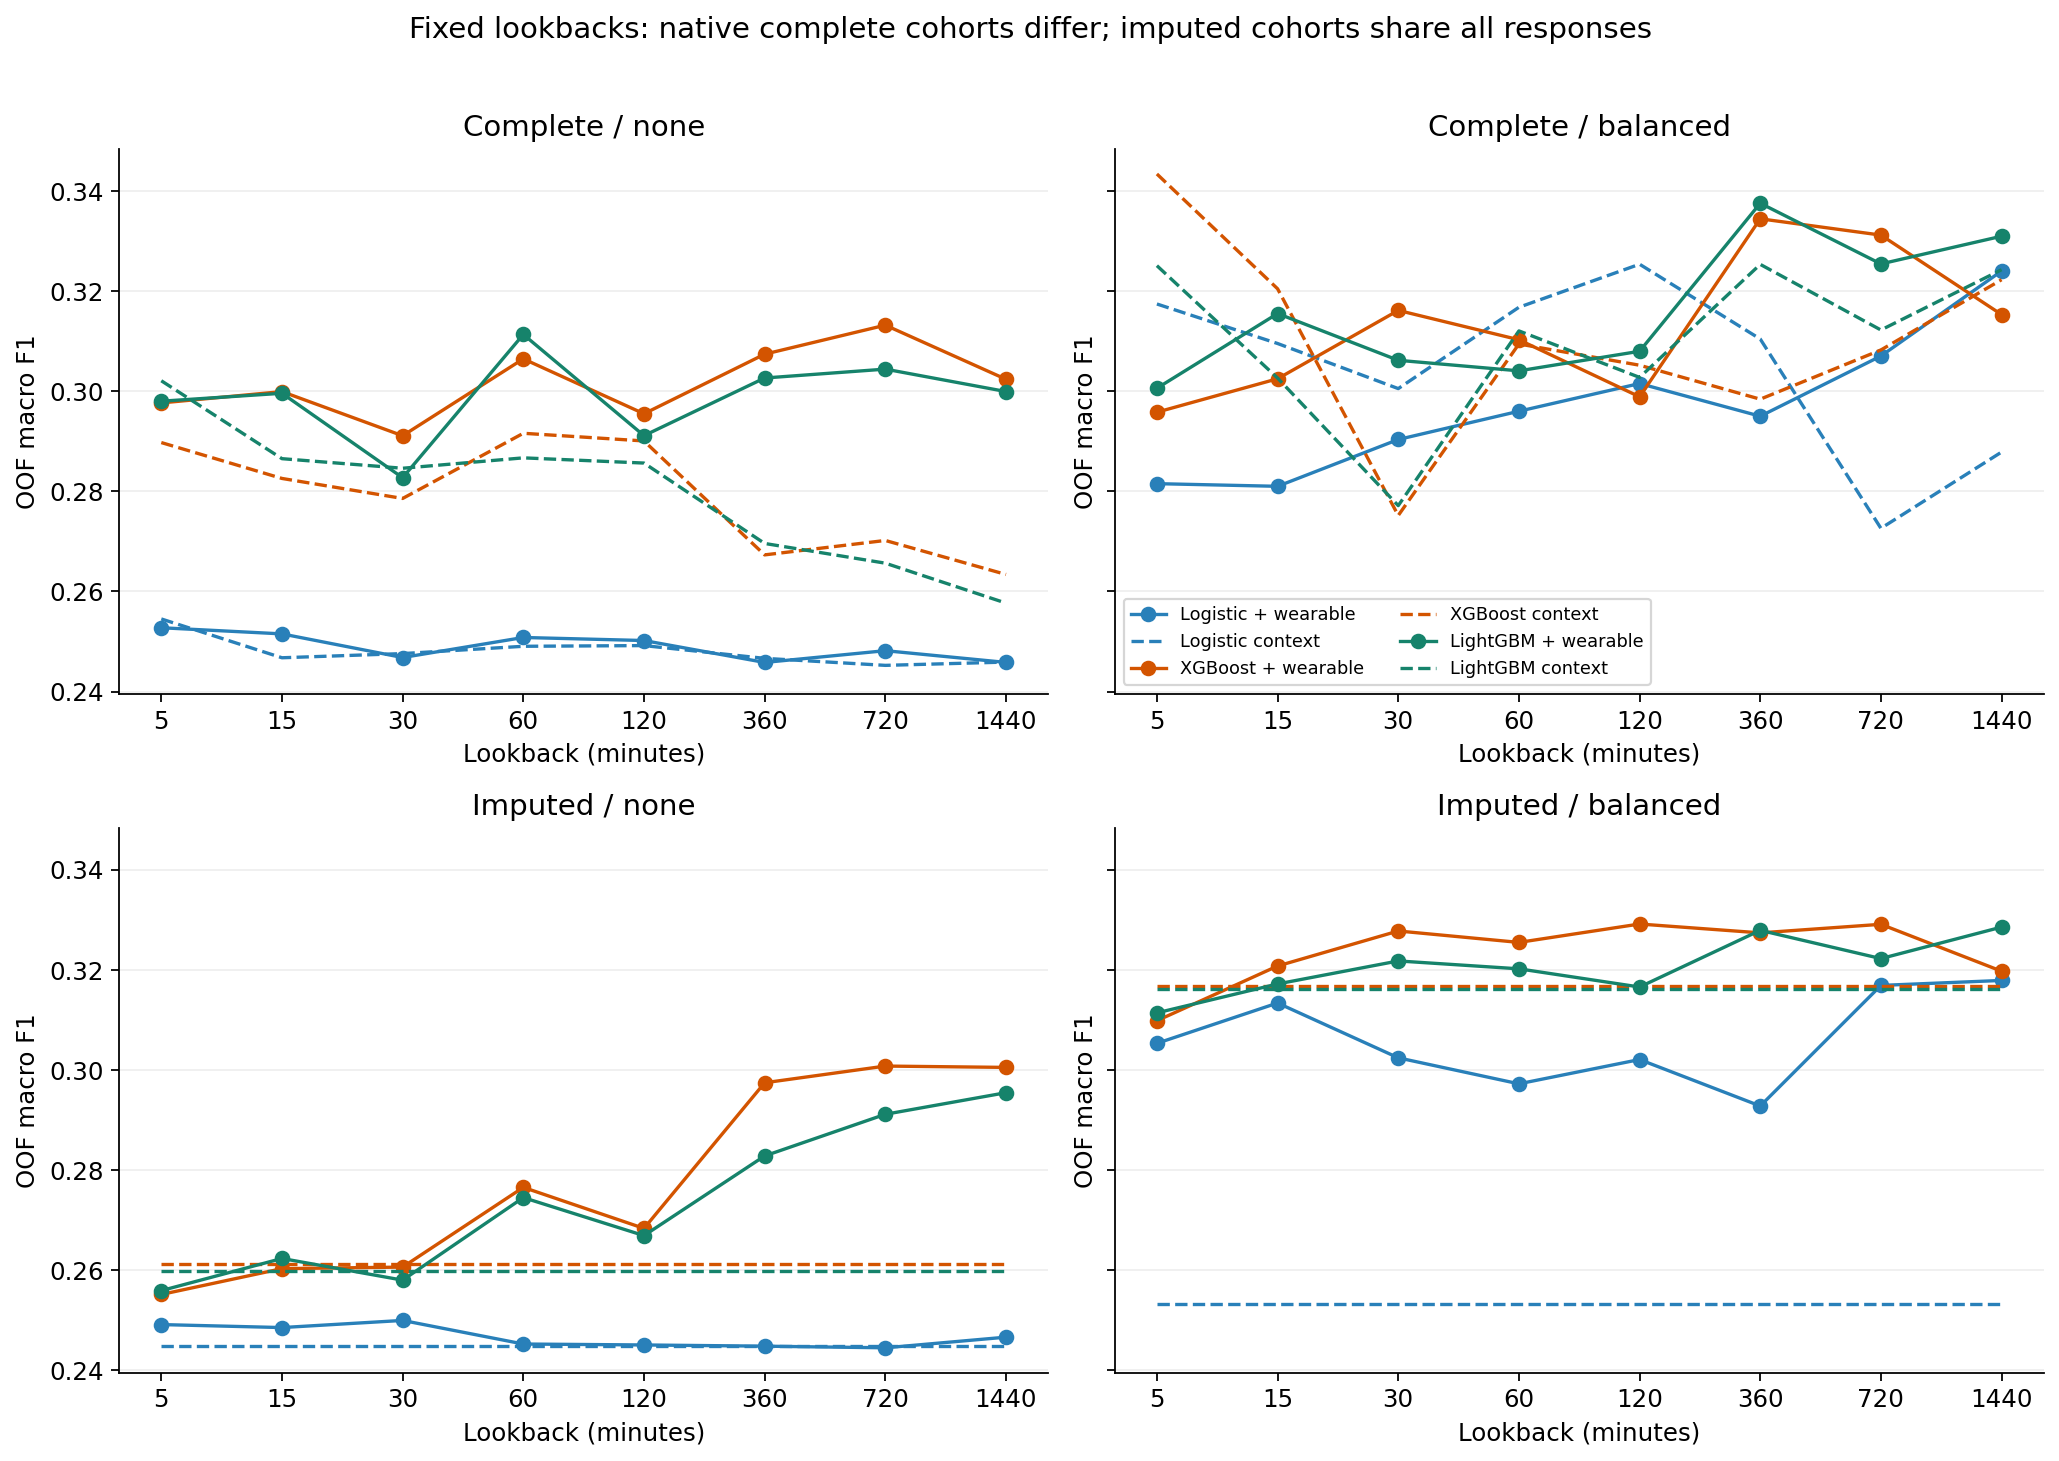

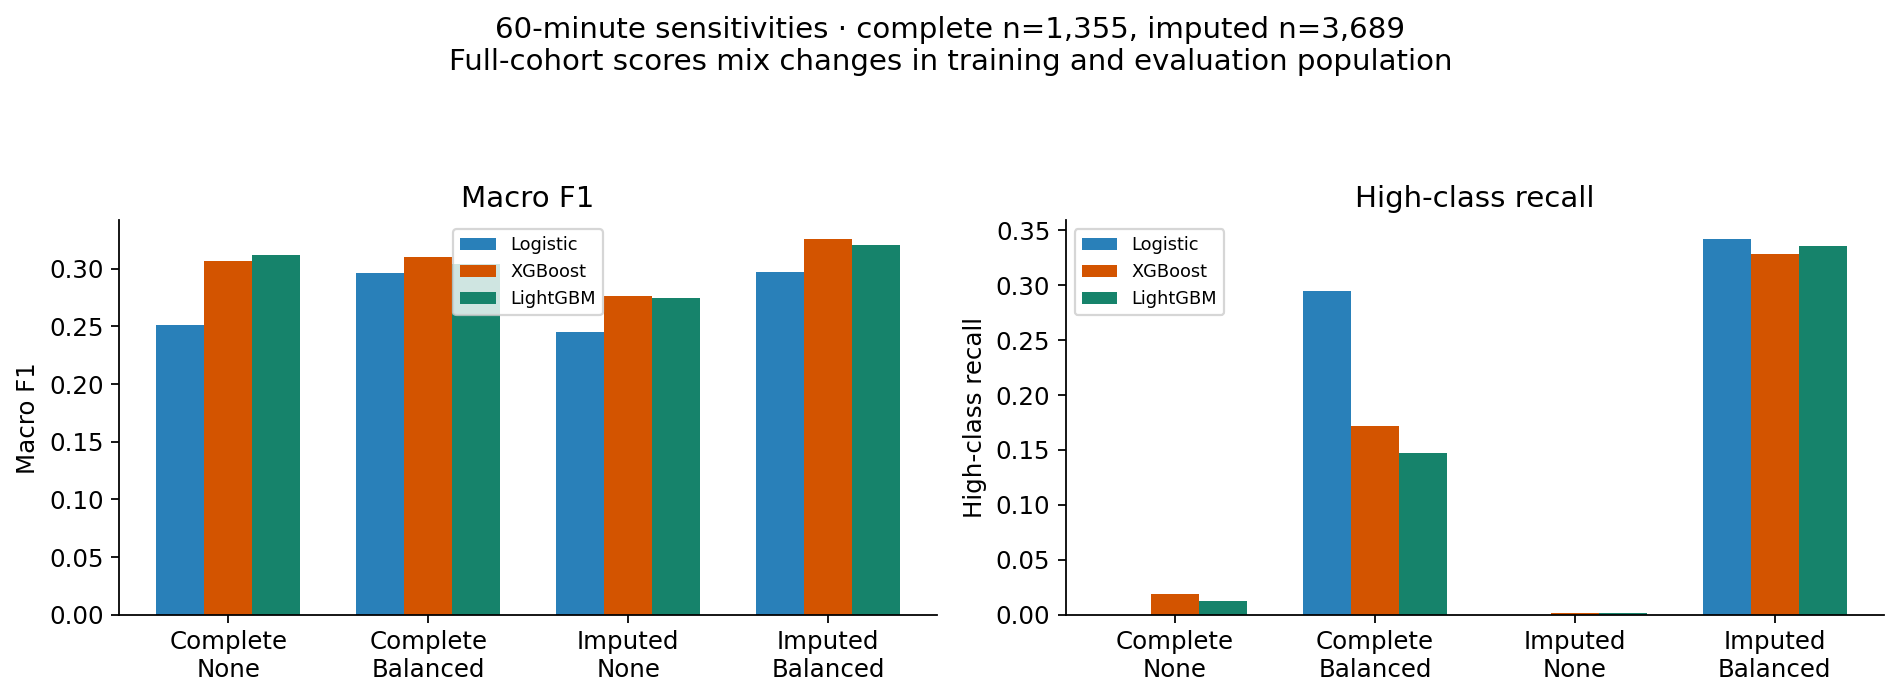

In [8]:
figure('05_lookbacks')
figure('08_weighting_and_handling')

In [9]:
common = table('common_lookback_metrics')
display(common.query("view == 'context_hr_steps' and weighting == 'none'")[[ 'minutes','model','responses','participants','macro_f1','elevated_recall']])

,minutes,model,responses,participants,macro_f1,elevated_recall
13,120,lightgbm,625,104,0.303,0.026
15,120,logistic,625,104,0.251,0.000
17,120,xgboost,625,104,0.311,0.013
32,1440,lightgbm,625,104,0.282,0.000
34,1440,logistic,625,104,0.252,0.000
36,1440,xgboost,625,104,0.290,0.000
51,15,lightgbm,625,104,0.325,0.026
53,15,logistic,625,104,0.260,0.000
55,15,xgboost,625,104,0.320,0.026
70,30,lightgbm,625,104,0.293,0.000


### Is imputation helping through physiology or availability?
Left: imputed versus complete models scored on identical complete validation responses; training cohorts differ.
Right: physiological values plus missingness versus context plus missingness alone, on identical all-valid cohorts.
A missingness flag represents the recording process, not physiological stress.

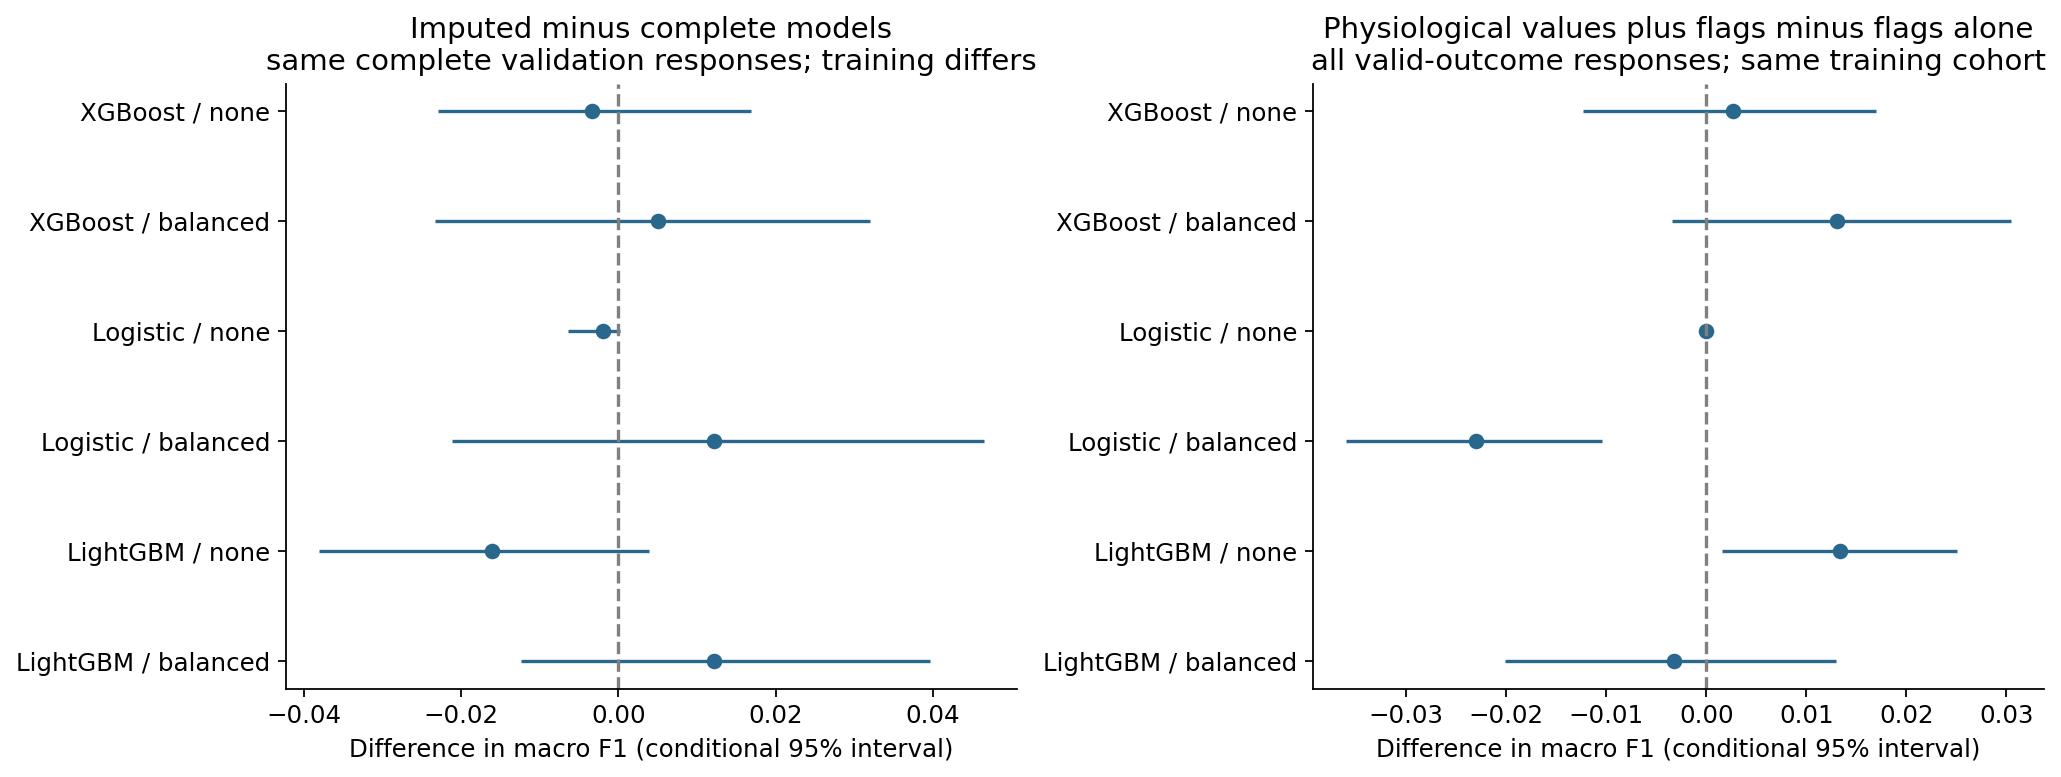

In [10]:
figure('06_missingness_matched')

### Secondary binary and earlier-reference checks
The ≥5 task includes middle and high responses as positive; its positive-class metrics are not high-only detection.
The ≥10 task specifically tests the high threshold. Reference history excludes the current hour and requires
30 occupied minutes over three UTC-hour bins before being available. It is not resting HR.

In [11]:
display(metrics.query("task != 'three_class' and view == 'context_hr_steps'")[[ 'task','handling','model','weighting','responses','macro_f1','elevated_precision','elevated_recall','roc_auc']])
display(differences.query("comparison == 'incremental_history'")[[ 'experiment','model','weighting','responses','macro_f1_difference','difference_low','difference_high']])

,task,handling,model,weighting,responses,macro_f1,elevated_precision,elevated_recall,roc_auc
12,at_least_10,complete,lightgbm,balanced,1355,0.487,0.113,0.196,0.418
13,at_least_10,complete,lightgbm,none,1355,0.468,0.000,0.000,0.428
14,at_least_10,complete,logistic,balanced,1355,0.427,0.117,0.448,0.482
15,at_least_10,complete,logistic,none,1355,0.468,0.000,0.000,0.436
16,at_least_10,complete,xgboost,balanced,1355,0.476,0.085,0.104,0.395
17,at_least_10,complete,xgboost,none,1355,0.468,0.000,0.000,0.442
31,at_least_10,imputed,lightgbm,balanced,3689,0.466,0.142,0.386,0.517
32,at_least_10,imputed,lightgbm,none,3689,0.462,0.000,0.000,0.513
33,at_least_10,imputed,logistic,balanced,3689,0.450,0.151,0.503,0.520
34,at_least_10,imputed,logistic,none,3689,0.462,0.000,0.000,0.511


,experiment,model,weighting,responses,macro_f1_difference,difference_low,difference_high
1114,three_class__60m__history__complete,lightgbm,balanced,1312,-0.003,-0.028,0.021
1119,three_class__60m__history__complete,lightgbm,none,1312,0.007,-0.013,0.027
1123,three_class__60m__history__complete,logistic,balanced,1312,-0.032,-0.052,-0.014
1127,three_class__60m__history__complete,logistic,none,1312,0.001,-0.002,0.006
1130,three_class__60m__history__complete,xgboost,balanced,1312,0.001,-0.026,0.027
1135,three_class__60m__history__complete,xgboost,none,1312,-0.005,-0.035,0.022
1215,three_class__60m__history__imputed,lightgbm,balanced,3689,0.001,-0.017,0.018
1221,three_class__60m__history__imputed,lightgbm,none,3689,-0.002,-0.012,0.009
1226,three_class__60m__history__imputed,logistic,balanced,3689,-0.026,-0.047,-0.008
1231,three_class__60m__history__imputed,logistic,none,3689,0.002,-0.000,0.006


### Interpretation checks: importance and fold stability
Permutation importance measures the drop in held-out macro F1 when an input is shuffled. Small or negative
values indicate little stable contribution under this perturbation, not proof of biological irrelevance.
Correlated summaries can substitute for each other. No importance result is used to select features.

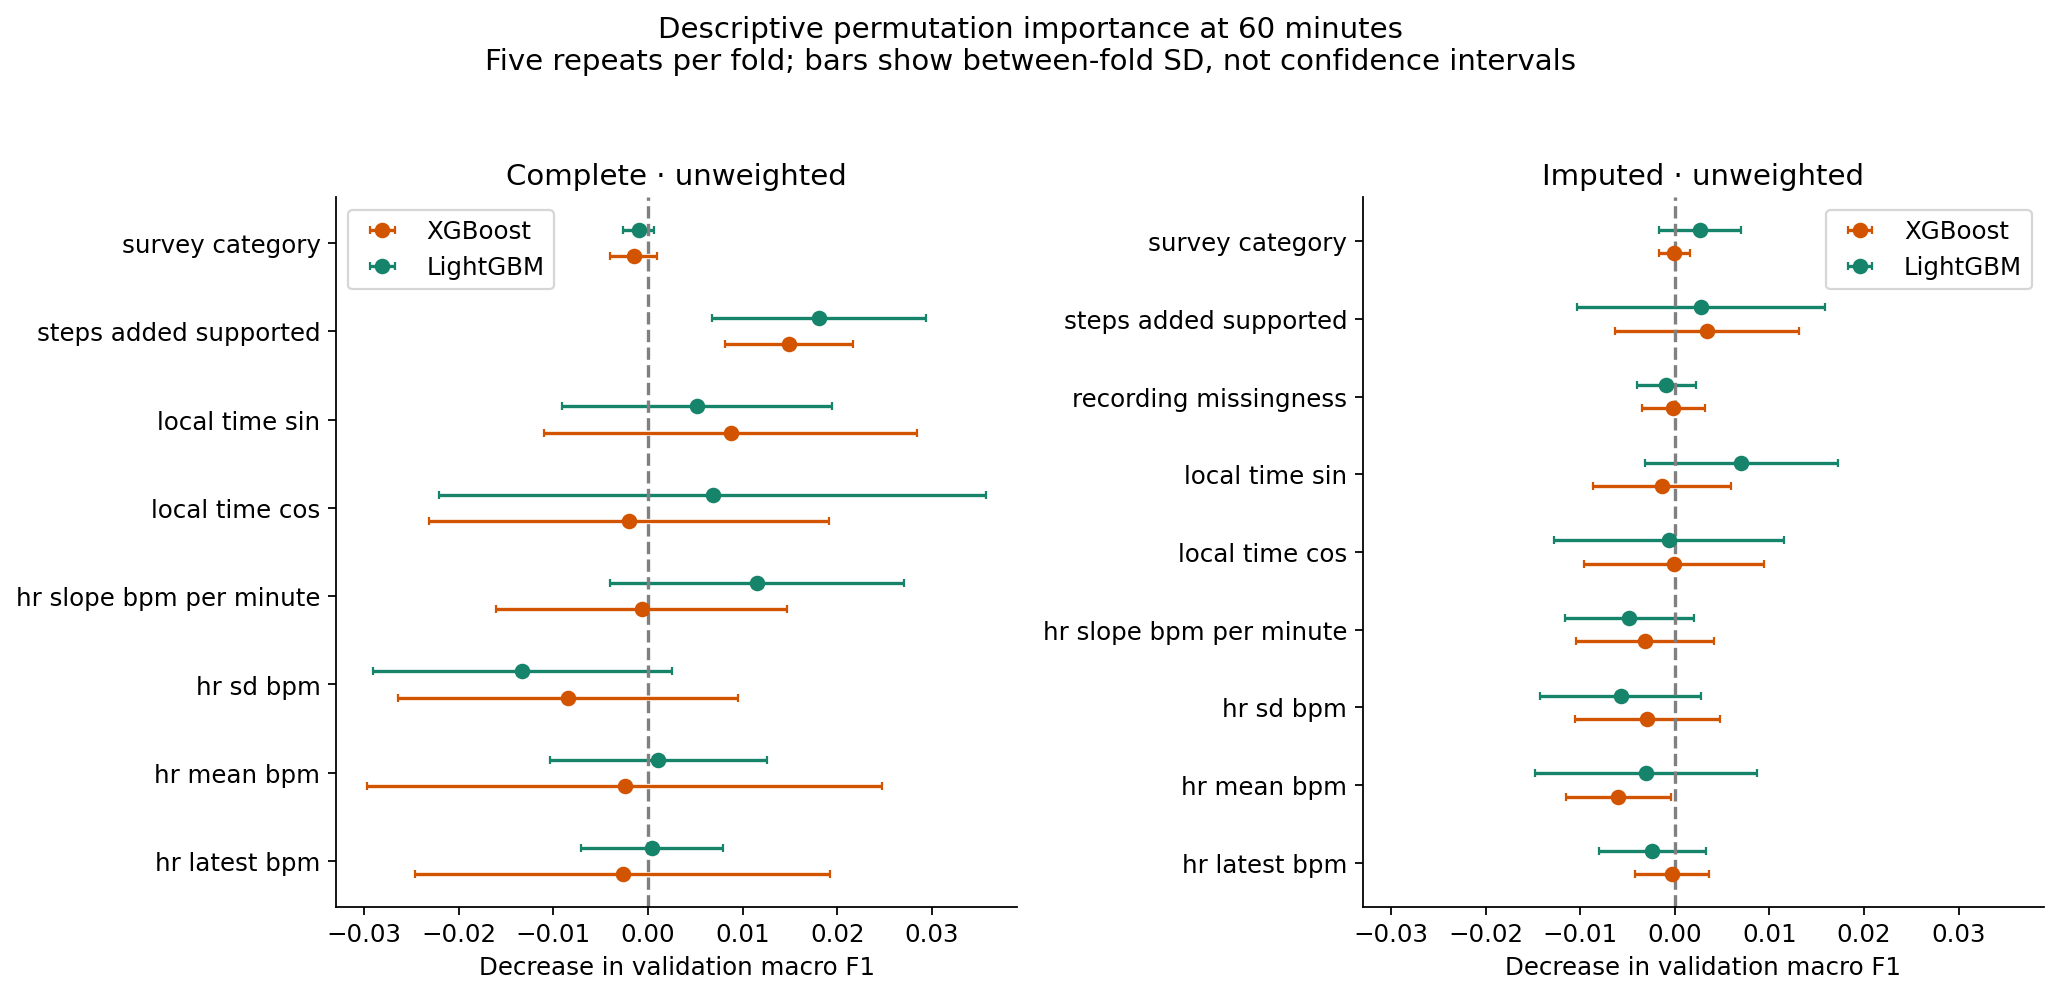

,fold,model,weighting,training_macro_f1,validation_macro_f1
583,0,logistic,none,0.246,0.266
584,0,xgboost,none,0.585,0.301
585,0,lightgbm,none,0.697,0.355
586,0,logistic,balanced,0.333,0.298
587,0,xgboost,balanced,0.496,0.272
588,0,lightgbm,balanced,0.830,0.298
602,1,logistic,none,0.252,0.236
603,1,xgboost,none,0.825,0.279
604,1,lightgbm,none,0.697,0.288
605,1,logistic,balanced,0.298,0.313


In [12]:
figure('07_permutation_importance')
training = table('training')
display(training.query("experiment == 'three_class__60m__joint__complete' and view == 'context_hr_steps'")[[ 'fold','model','weighting','training_macro_f1','validation_macro_f1']])

In [13]:
settings = table('settings')
display(settings.query("experiment == 'three_class__60m__joint__complete' and view == 'context_hr_steps' and weighting == 'none'")[[ 'fold','model','selected_index','selected_params','converged']])

,fold,model,selected_index,selected_params,converged
552,0,logistic,3,{'C': 10.0},True
553,0,xgboost,9,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",True
554,0,lightgbm,3,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...",True
570,1,logistic,2,{'C': 1.0},True
571,1,xgboost,3,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",True
572,1,lightgbm,3,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...",True
588,2,logistic,2,{'C': 1.0},True
589,2,xgboost,3,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",True
590,2,lightgbm,3,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...",True
606,3,logistic,2,{'C': 1.0},True


### Findings, limitations and the next justified experiment
The following abstract is generated from the actual saved results. The full report includes matched
bootstrap comparisons, coverage, secondary checks and unresolved measurement questions.

In [14]:
display(Markdown((ROOT / 'reports/pss_classification/abstract.md').read_text()))

# Exploratory classification of a three-item perceived-stress composite from Garmin–EMA data

**Objective.** Assess whether recorded pre-EMA heart rate and activity distinguish exploratory perceived-stress
categories beyond survey and time-of-day context after earlier regression benchmarks showed weak performance.

**Methods.** We analyzed 3,706 responses from 125 development participants; 3,689 had valid three-item
composites (range 3–15), classified as low (3–4; n=1,033), middle (5–9; n=2,141), or high (10–15; n=515).
Five frozen participant-held-out folds contained three-fold grouped inner tuning for logistic regression,
XGBoost and LightGBM. Majority-class baselines and context/wearable models used matched cohorts.
The primary benchmark used unweighted 60-minute complete cases (1,355 responses; 113 participants).
Prespecified sensitivities examined eight lookbacks, class weighting, feature-level imputation, earlier
HR references and two binary cutoffs. Macro F1 was primary; intervals used paired participant bootstrapping.
All 32 final-test participants remained sealed.

**Results.** Primary context-plus-HR-plus-steps XGBoost and LightGBM achieved macro F1 of 0.306 and
0.311, versus 0.249 for the majority baseline and 0.251 for logistic regression. Increments over matching
context-only models were 0.015 (95% conditional interval −0.010 to 0.037) and 0.025 (−0.003 to 0.051).
Balanced accuracy was 0.335/0.338; high-class recall was 1.8%/1.2%. Class weighting increased high
recall to 17.2%/14.7%, with precision 10.0%/9.3%. Some longer-window and imputed sensitivities showed
small positive context increments, but gains were inconsistent across weighting choices and did not
establish reliable high-score identification. Earlier HR references added no stable boosting benefit.

**Conclusion.** Classification exposed severe high-score detection failure despite macro-F1 gains over
a majority baseline. The primary experiment did not establish incremental wearable value beyond context.
Measurement timing, recall alignment, recording selection, limited independent participants and repeated
exploratory comparisons constrain interpretation. These categories are not clinical diagnoses; synchronized
measurement evidence and targeted independent validation are needed before any deployment claim.


### Verification and reproducibility
The fitted estimators, fold memberships, trial scores and individual predictions stay in ignored private
storage. Public results are aggregate only. No prior notebook, raw file, frozen assignment or final-test
outcome is changed. The notebook intentionally retains only these aggregate execution outputs.

Reproduce fitting from the repository environment:
```bash
PYTHONPATH=src MPLCONFIGDIR=/private/tmp/garmin-mpl OMP_NUM_THREADS=1 .venv/bin/python -m garmin_pss_classification.run
```
Completed immutable fold jobs are verified and reused. Aggregation and figure commands are documented
in `reports/pss_classification/README.md`; public output writers refuse to replace an existing result directory.

In [15]:
display(pd.DataFrame([json.loads((RESULTS / 'verification.json').read_text())]).T.rename(columns={0:'result'}))

,result
all_prediction_replays_agree,True
completed_fold_jobs,115
corrected_input_bundles_verified,True
development_participants,125
development_rows,3706
final_test_participants_evaluated,0
missing_targets,17
original_assignment_checksum_verified,True
participant_separation_verified,True
preserved_prior_manifests,22
